# Coverage visualizations

Reads `gaps.csv` and `visit_summary_corrected.csv` (from `discontinuity_corrections.py`'s `--gaps`/`--visits`)
and shows:

1. Gap duration histograms (overall, and per patient)
2. Gap counts per patient
3. Good-data intervals (the complement of the gap intervals within each admission's recorded span)
4. Good-data duration histograms (overall, and per patient)

`gaps.csv` is already the reduced/corrected gap list (insane-discontinuity artifacts resolved into
either a real gap or excluded, per category - see `scripts/discontinuity_types.md`), so no separate
imputed-gap file needs to be unioned in here.

Two diagnostic sections further down (tiny `other`-cause gaps, TOC-reset gaps 3-15 minutes) instead
read `discontinuity_labeled.csv` - the full per-row discontinuity log with `cause`/`brk_ts_before`,
which `gaps.csv` doesn't carry (it's one row per real-world gap event, not per raw discontinuity).

In [1]:
import math
from math import floor

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from plotting_utils import log_bins, hist_ax, small_multiples, stacked_bars, raw_values_by_group

GAP_SUMMARY_CSV = '../phi-data/detailedv2/gaps.csv'  # discontinuity_corrections.py --gaps output
VISIT_SUMMARY_CSV = '../phi-data/detailedv2/visit_summary_corrected.csv'  # discontinuity_corrections.py --visits output
DISCONTINUITY_LABELED_CSV = '../phi-data/detailedv2/discontinuity_labeled.csv'  # discontinuity_corrections.py --labels output
UNTRUSTWORTHY_CSV = '../phi-data/detailedv2/untrustworthy_ranges.csv'
PACKET_SUMMARY_CSV = '../phi-data/detailedv2/packet_summary.csv'

gaps = pd.read_csv(GAP_SUMMARY_CSV, parse_dates=['gap_start_utc', 'gap_end_utc'])
gaps['duration_hours'] = gaps['duration_seconds'] / 3600

visits = pd.read_csv(VISIT_SUMMARY_CSV, parse_dates=['recording_start_utc', 'recording_end_utc'])

disc_labeled = pd.read_csv(
    DISCONTINUITY_LABELED_CSV, parse_dates=['start_utc', 'end_utc']
).rename(columns={'start_utc': 'gap_start_utc', 'end_utc': 'gap_end_utc'})

untrustworthy = pd.read_csv(UNTRUSTWORTHY_CSV)
packets = pd.read_csv(PACKET_SUMMARY_CSV)

print(f'{len(gaps)} gaps across {gaps["emu_id"].nunique()} patient(s)')
print(f'{len(visits)} admission(s) across {visits["emu_id"].nunique()} patient(s)')
print(f'{len(disc_labeled)} raw discontinuities across {disc_labeled["emu_id"].nunique()} patient(s)')
gaps.head()

793 gaps across 29 patient(s)
29 admission(s) across 29 patient(s)
16234 raw discontinuities across 29 patient(s)


,category,patient_id,emu_id,admission_id,toc_id_before,toc_id_after,gap_start_utc,gap_end_utc,duration_seconds,real_seconds,datapoint_seconds,anchor_chunk,anchor_packet,anchor_n_points,duration_hours
0,simple_gap,1,YFA,1,26,27,2024-04-23 14:55:54.375000,2024-04-23 15:03:47.365000,472.990000,NaN,NaN,NaN,NaN,NaN,0.131386
1,simple_gap,1,YFA,1,27,36,2024-04-23 17:12:38.354600,2024-04-23 17:14:33.364000,115.009400,NaN,NaN,NaN,NaN,NaN,0.031947
2,simple_gap,1,YFA,1,28,28,2024-04-23 18:04:17.866466,2024-04-23 18:25:27.361800,1269.495333,NaN,NaN,NaN,NaN,NaN,0.352638
3,simple_gap,1,YFA,1,28,29,2024-04-23 22:13:15.206000,2024-04-23 22:13:52.283000,37.077000,NaN,NaN,NaN,NaN,NaN,0.010299
4,simple_gap,1,YFA,1,29,29,2024-04-24 09:54:44.117000,2024-04-24 09:54:44.127033,0.010033,NaN,NaN,NaN,NaN,NaN,0.000003


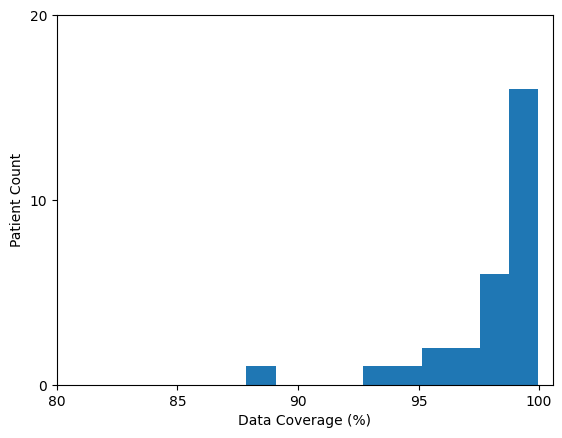

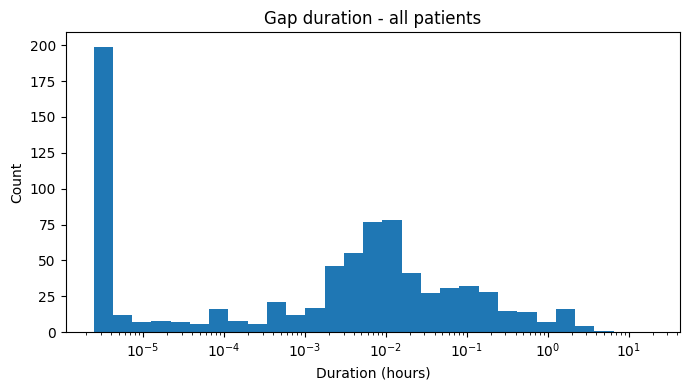

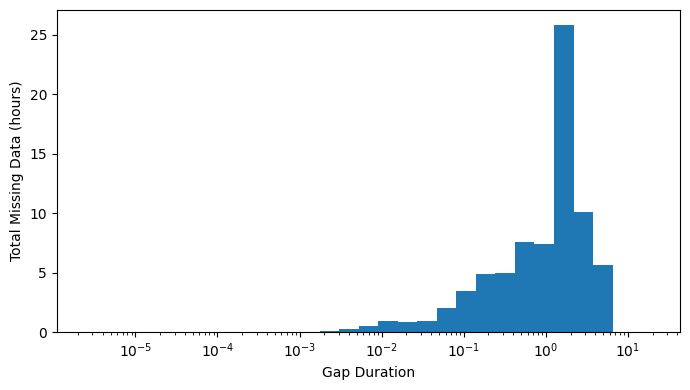

In [2]:
# Simple visualization of per-patient coverage
plt.hist(visits['pct_coverage'])
plt.gca().set_yticks([0, 10, 20])
plt.gca().set_xticks([80, 85, 90, 95, 100])
plt.xlabel('Data Coverage (%)')
plt.ylabel('Patient Count')

fig, ax = plt.subplots(figsize=(7, 4))
hist_ax(ax, gaps['duration_hours'], 'Gap duration - all patients', use_log=True)
plt.xscale('log')
plt.tight_layout()

fig, ax = plt.subplots(figsize=(7, 4))
bins = log_bins(gaps['duration_hours'], n=30)
plt.hist(gaps['duration_hours'], weights=gaps['duration_hours'], bins=bins)
plt.xscale('log')
plt.ylabel('Total Missing Data (hours)')
plt.xlabel('Gap Duration')
plt.tight_layout()
plt.show()

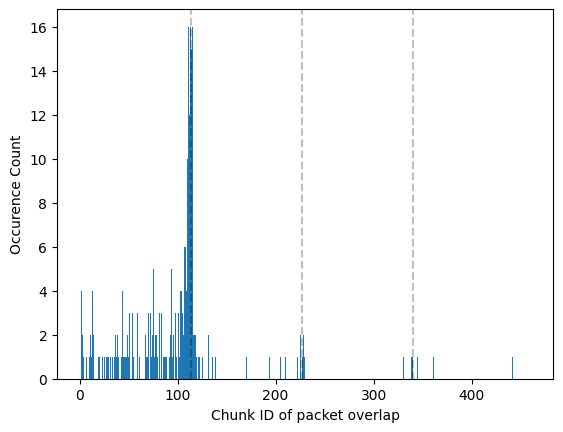

In [3]:
# Simple visualizations of the
overlaps = untrustworthy[untrustworthy['category'] == 'packet_overlap']
start_chunks = overlaps['first_chunk']

# Calculate weighting, based on how often different chunks occur
chunk_keys = packets[['patient_id', 'toc_id', 'chunk_id']].drop_duplicates(ignore_index=True)
n_chunks = len(chunk_keys)
chunk_counts = chunk_keys['chunk_id'].value_counts().sort_index()
most_common = chunk_counts.iloc[0]
chunk_weights = (most_common-chunk_counts+1)/n_chunks
weights = chunk_weights[start_chunks]

bins = np.arange(0, max(chunk_keys['chunk_id'])+1)
counts, bins, _ = plt.hist(start_chunks, bins=bins) # , weights=weights)
plt.xlabel('Chunk ID of packet overlap')
plt.ylabel('Occurence Count')

max_bin = np.argmax(counts)
# common_bins = bins[1:][counts >= 7]
# bin_prev, bin_end = common_bins[0]-1, common_bins[-1]+1
# in_range = np.logical_and(bin_prev < start_chunks, start_chunks <= bin_end)
# print(f'Most ({np.sum(in_range)}/{len(start_chunks)}) datapoints are between {bin_prev} and {bin_end}')
ylims = plt.gca().get_ylim()
for i in range(1, 4):
    x = 113.5 * i
    plt.plot([x, x], ylims, linestyle='--', color='black', alpha=0.25)
_ = plt.ylim(ylims)
# Conclusion: packet overlaps tend to happen vary preferentially near to chunk ~113, even though
# most toc recordings don't have that many chunks

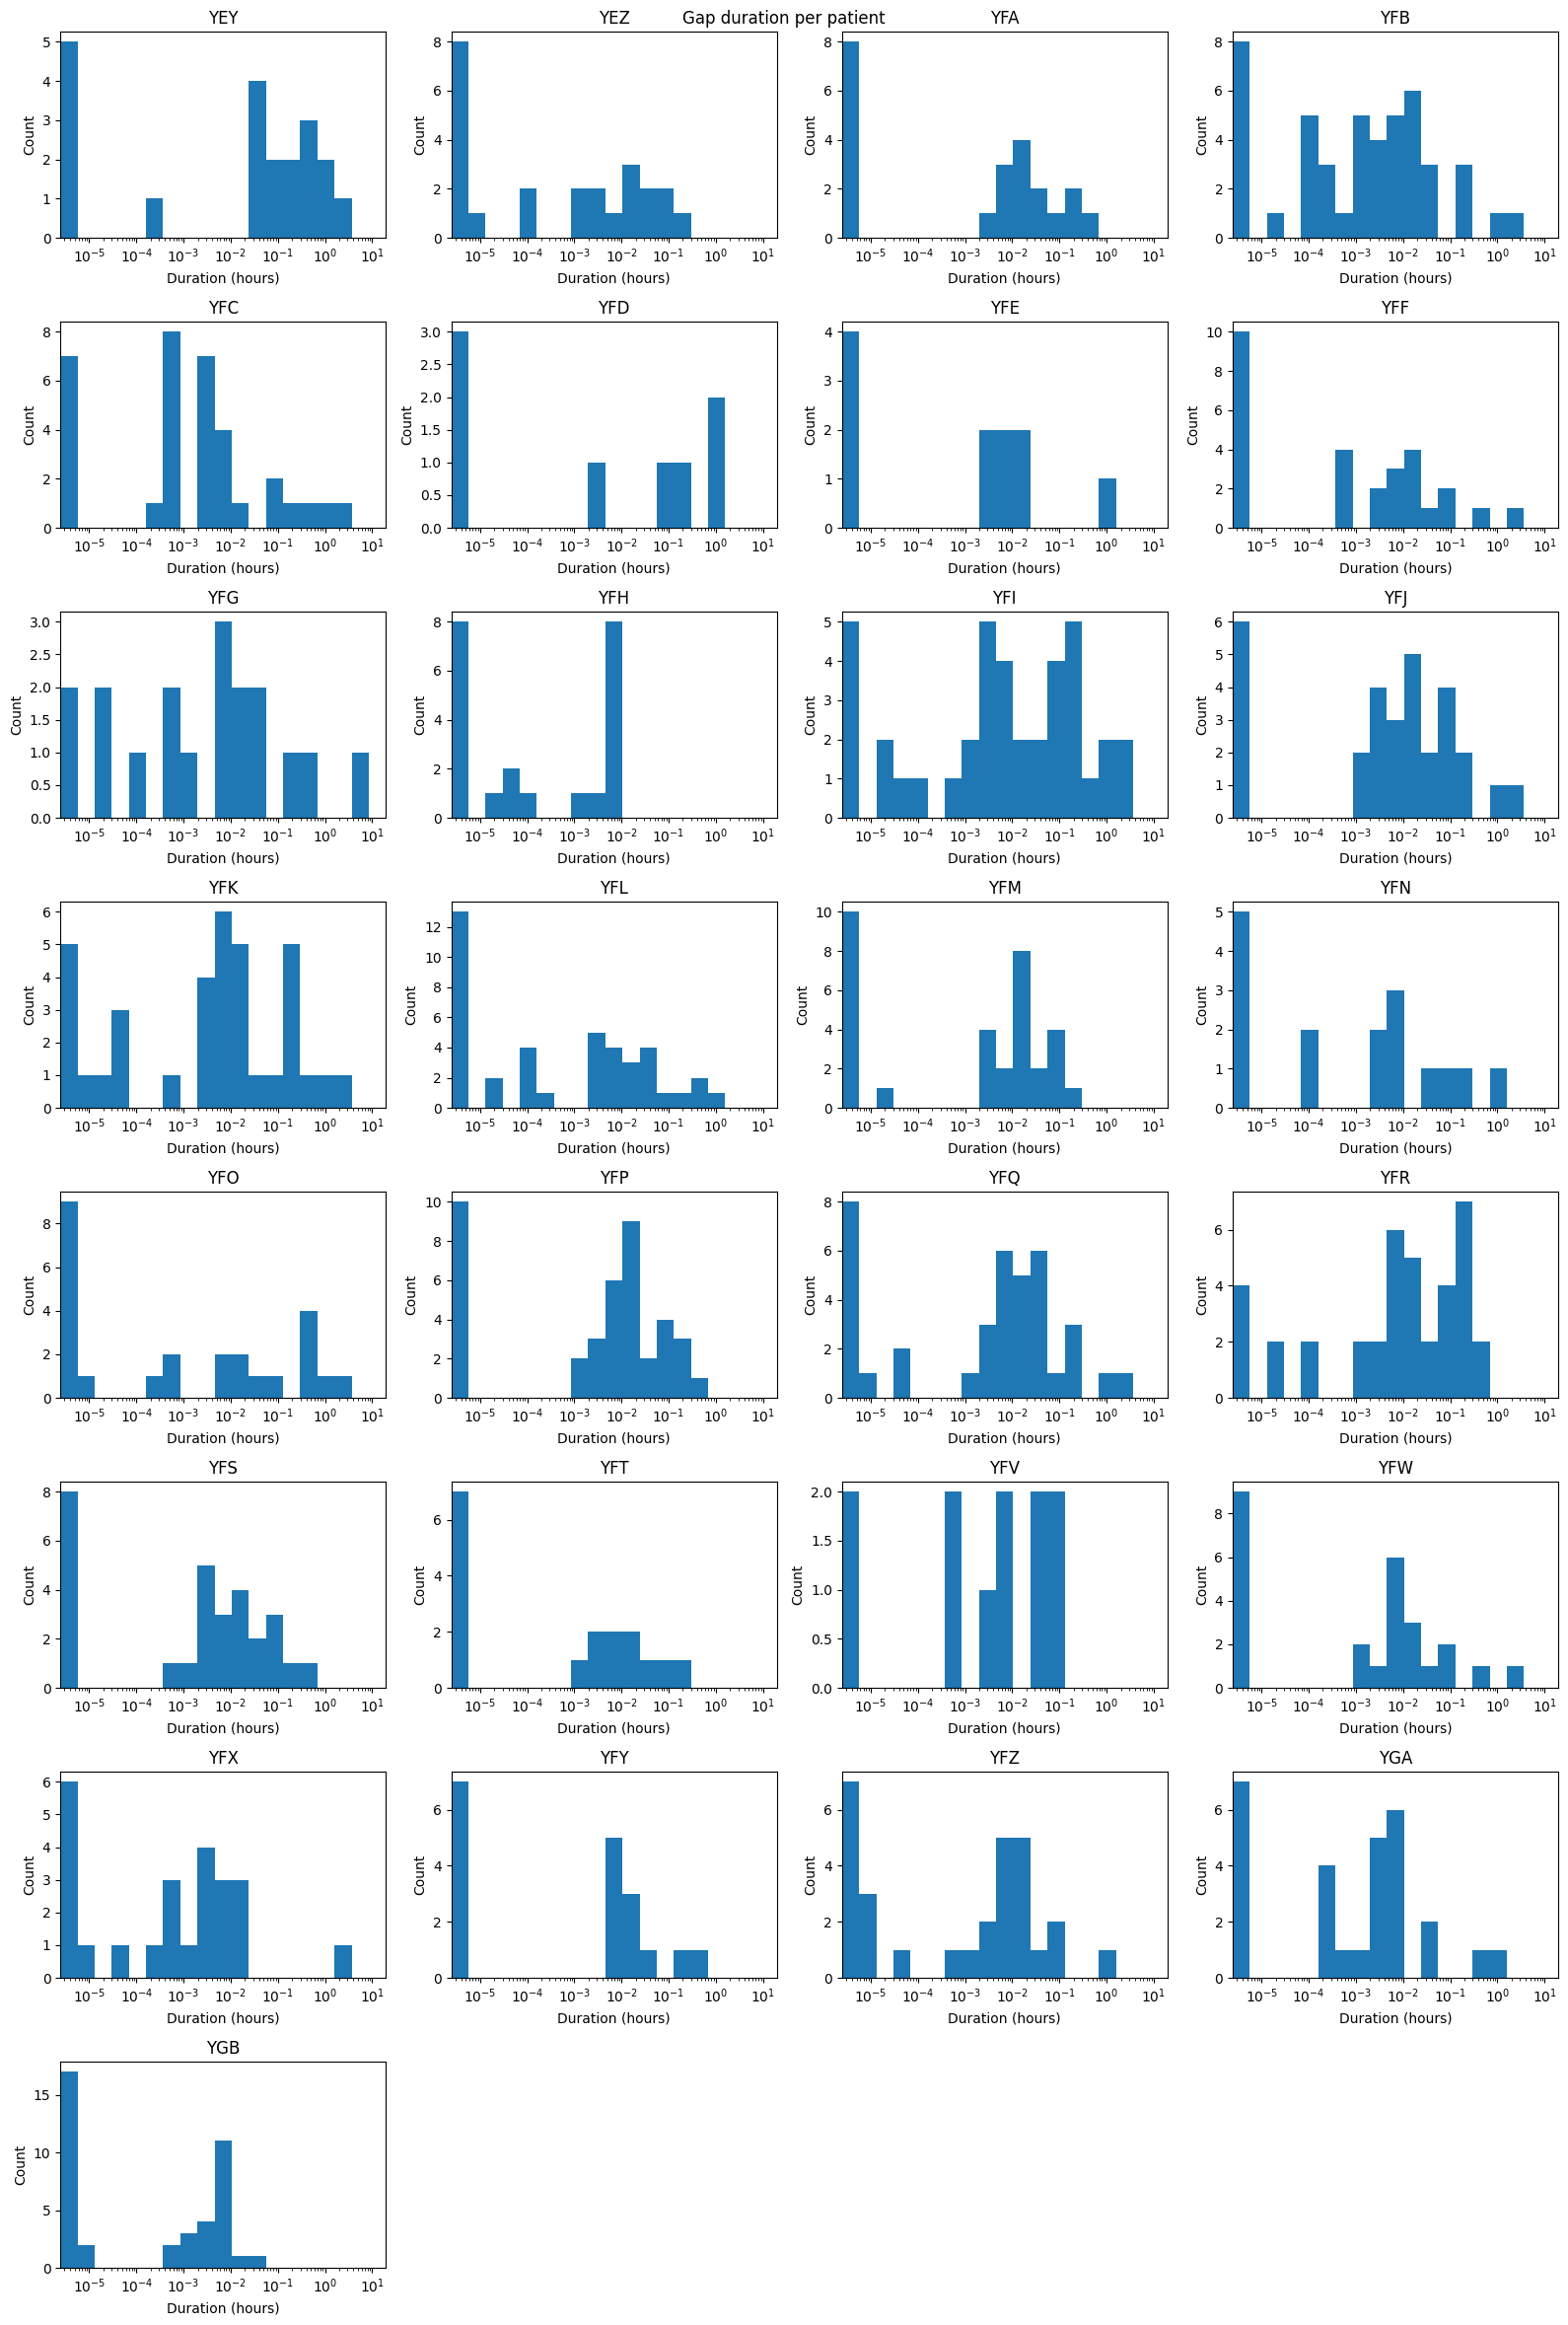

In [4]:
small_multiples(gaps, 'duration_hours', 'emu_id', 'Gap duration per patient')

## Gap counts per patient

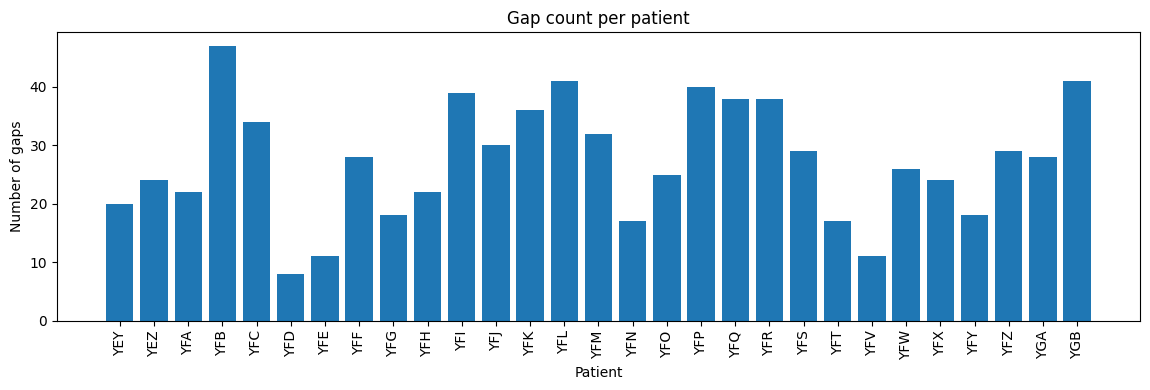

In [5]:
gap_counts = gaps.groupby('emu_id').size()

fig, ax = plt.subplots(figsize=(max(6, 0.4 * len(gap_counts)), 4))
ax.bar(gap_counts.index.astype(str), gap_counts.values)
ax.set_xlabel('Patient')
ax.set_ylabel('Number of gaps')
ax.set_title('Gap count per patient')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


## Good-data intervals

For each admission, take its `[recording_start_utc, recording_end_utc]` span from
`visit_summary_corrected.csv` and subtract every gap interval from `gaps.csv` (sorted by start) to
get the complementary continuous "good data" spans - the recording start to the first gap, the
space between each pair of consecutive gaps, and the last gap to the recording end.

In [6]:
def good_intervals_for_admission(recording_start, recording_end, admission_gaps):
    """Complement of admission_gaps (sorted by start) within [recording_start, recording_end]."""
    admission_gaps = admission_gaps.sort_values('gap_start_utc')

    intervals = []
    cursor = recording_start
    for _, gap in admission_gaps.iterrows():
        if gap['gap_start_utc'] > cursor:
            intervals.append((cursor, gap['gap_start_utc']))
        cursor = max(cursor, gap['gap_end_utc'])
    if recording_end > cursor:
        intervals.append((cursor, recording_end))
    return intervals


rows = []
for _, visit in visits.iterrows():
    admission_gaps = gaps[
        (gaps['patient_id'] == visit['patient_id'])
        & (gaps['admission_id'] == visit['admission_id'])
    ]
    for good_start, good_end in good_intervals_for_admission(
        visit['recording_start_utc'], visit['recording_end_utc'], admission_gaps
    ):
        rows.append({
            'patient_id': visit['patient_id'],
            'emu_id': visit['emu_id'],
            'admission_id': visit['admission_id'],
            'good_start_utc': good_start,
            'good_end_utc': good_end,
            'duration_hours': (good_end - good_start).total_seconds() / 3600,
        })

good_intervals = pd.DataFrame(rows)
print(f'{len(good_intervals)} continuous good-data interval(s)')
good_intervals.head()

814 continuous good-data interval(s)


,patient_id,emu_id,admission_id,good_start_utc,good_end_utc,duration_hours
0,1,YFA,1,2024-04-23 01:03:01.899000,2024-04-23 14:55:54.375000,13.881243
1,1,YFA,1,2024-04-23 15:03:47.365000,2024-04-23 17:12:38.354600,2.147497
2,1,YFA,1,2024-04-23 17:14:33.364000,2024-04-23 17:35:07.610000,0.342846
3,1,YFA,1,2024-04-23 17:48:41.528000,2024-04-23 18:04:17.866466,0.260094
4,1,YFA,1,2024-04-23 18:25:27.361800,2024-04-23 22:13:15.206000,3.796623


## Good-data duration distributions

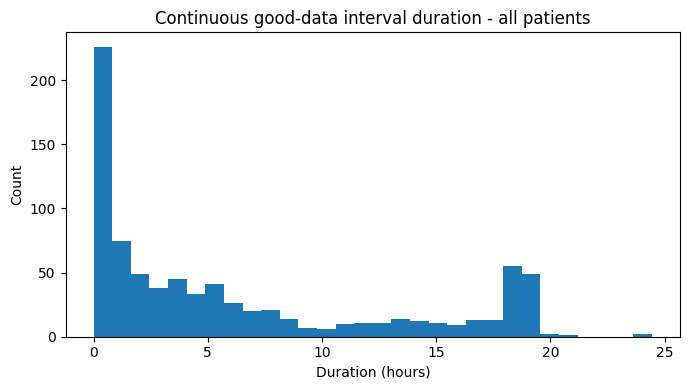

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
hist_ax(ax, good_intervals['duration_hours'], 'Continuous good-data interval duration - all patients')
plt.tight_layout()
plt.show()

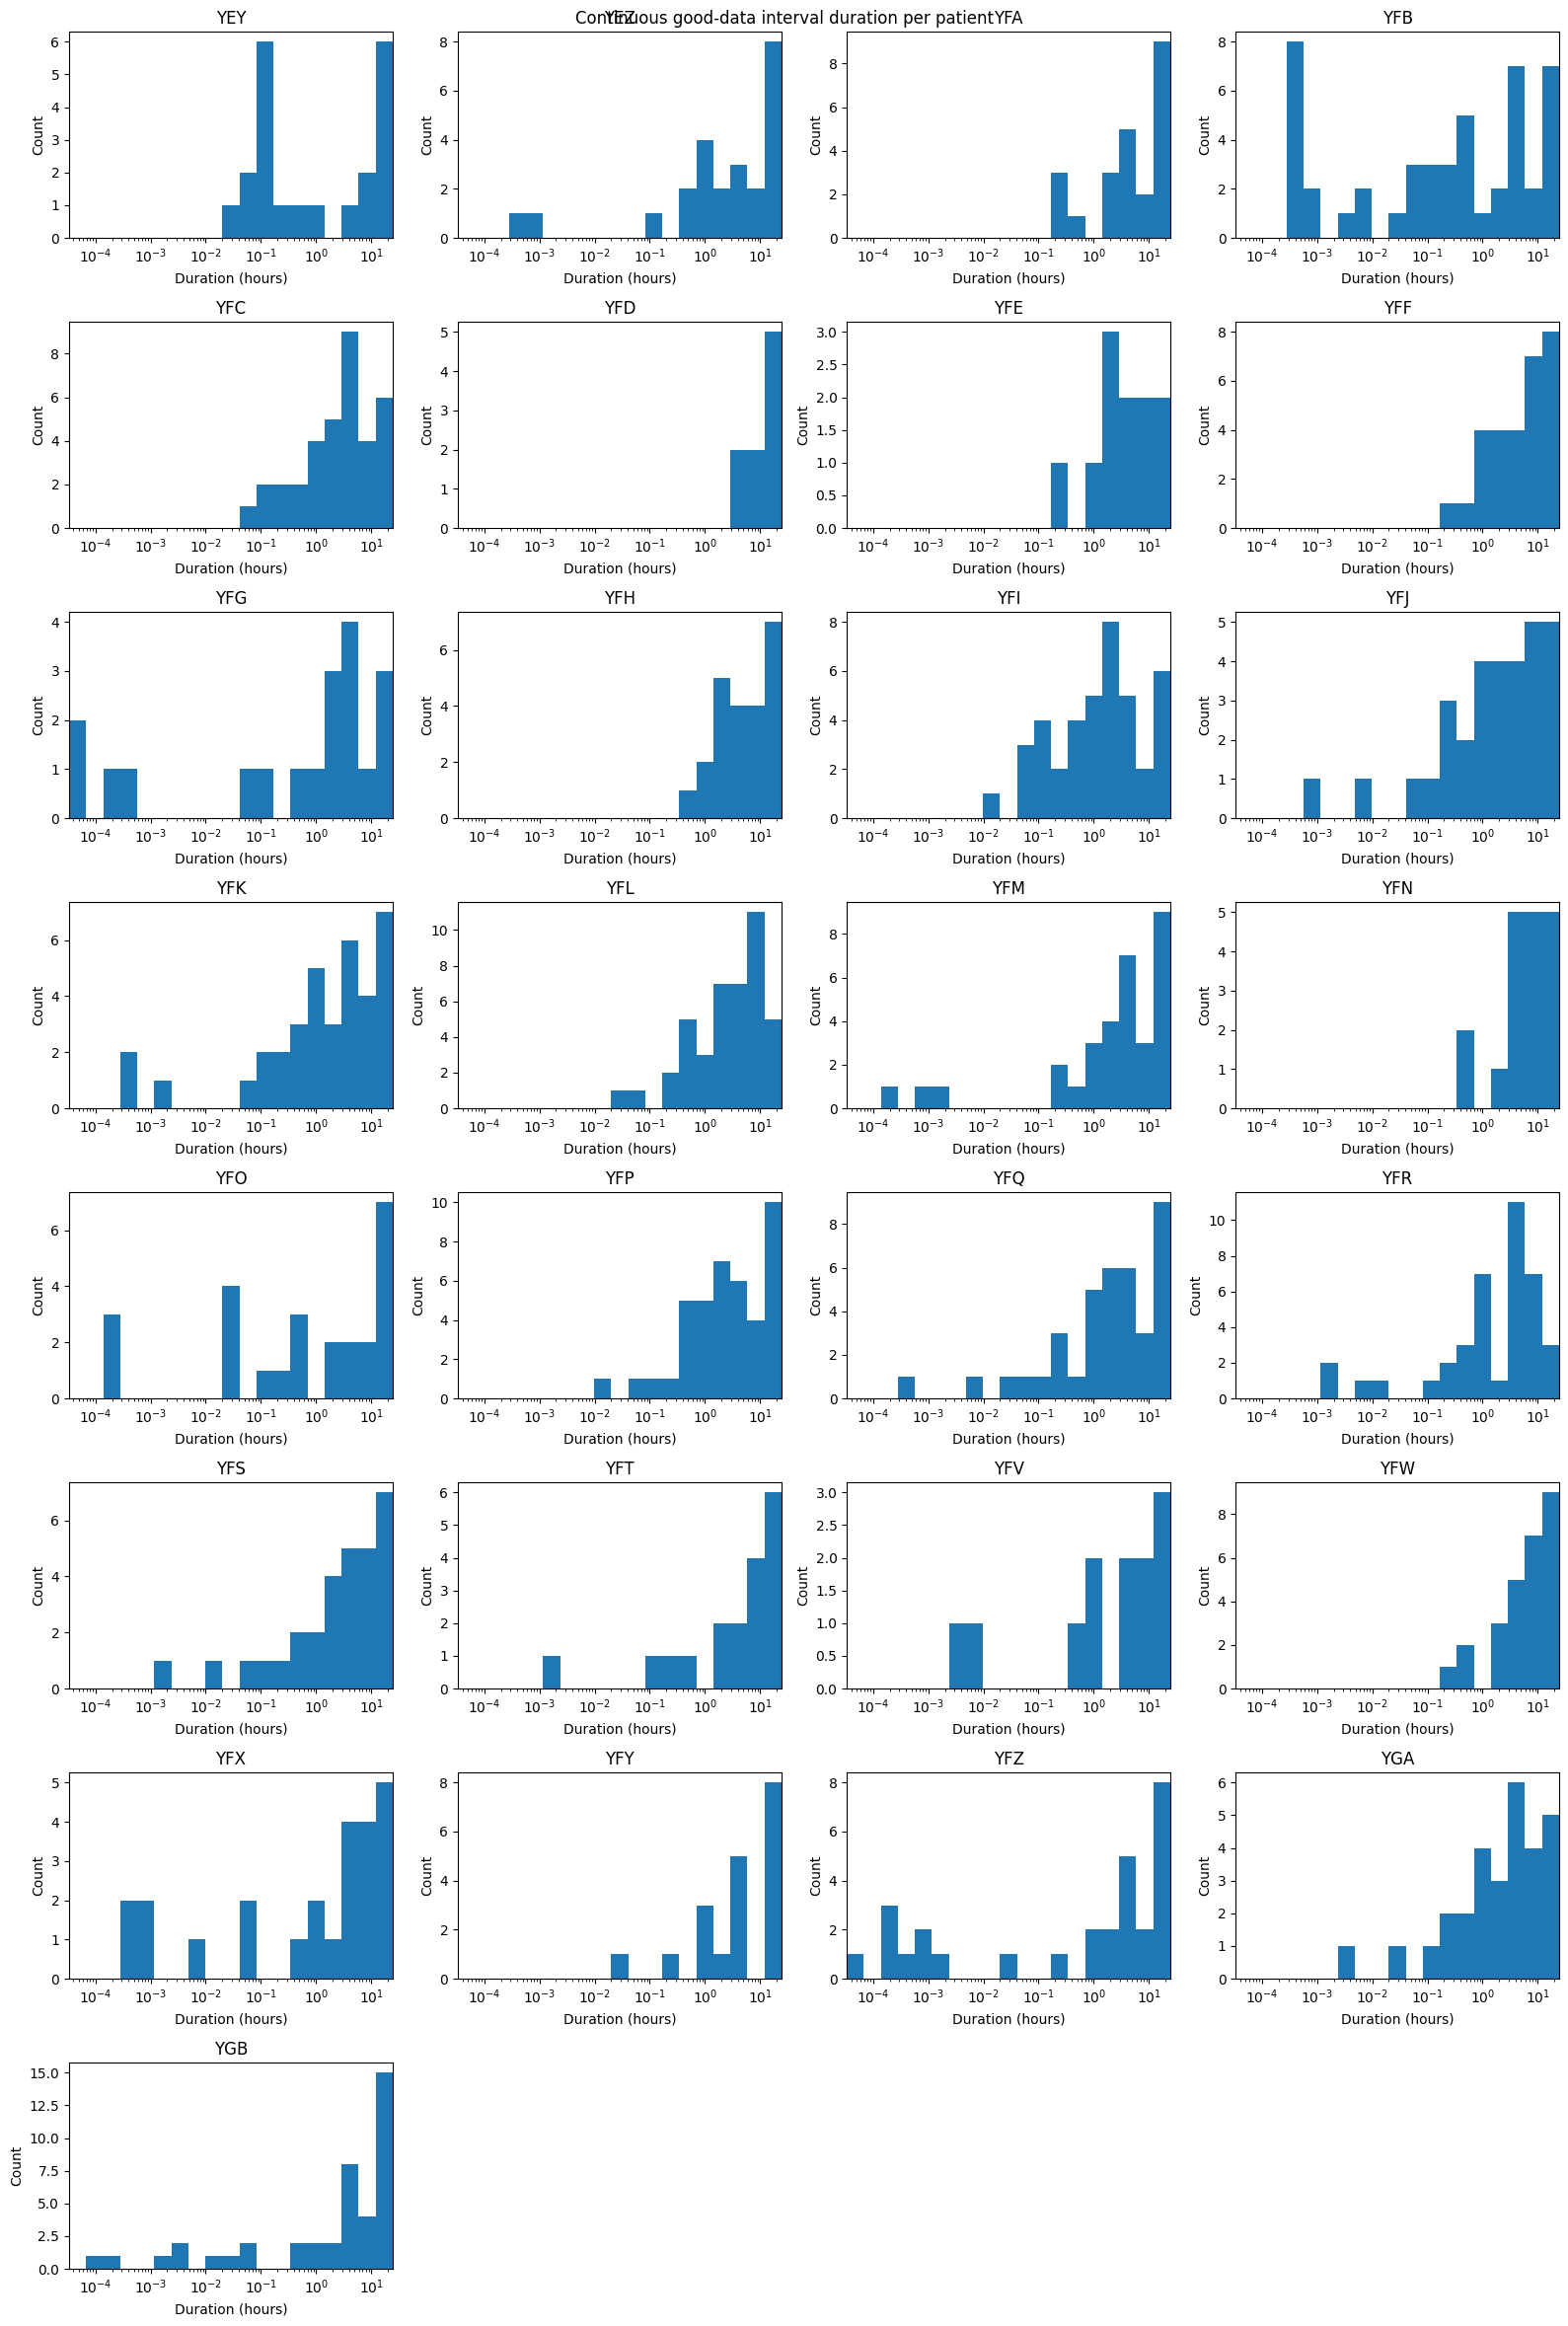

In [8]:
small_multiples(good_intervals, 'duration_hours', 'emu_id', 'Continuous good-data interval duration per patient')

## Per-patient recording timeline

One plot per patient, spanning that patient's whole recorded time course: available (good) data is a filled blue band, gaps are marked in red above it. A gap shorter than `SHORT_GAP_THRESHOLD_MINUTES` is drawn as a single point at its midpoint; a longer gap also gets a thin line spanning its full duration.

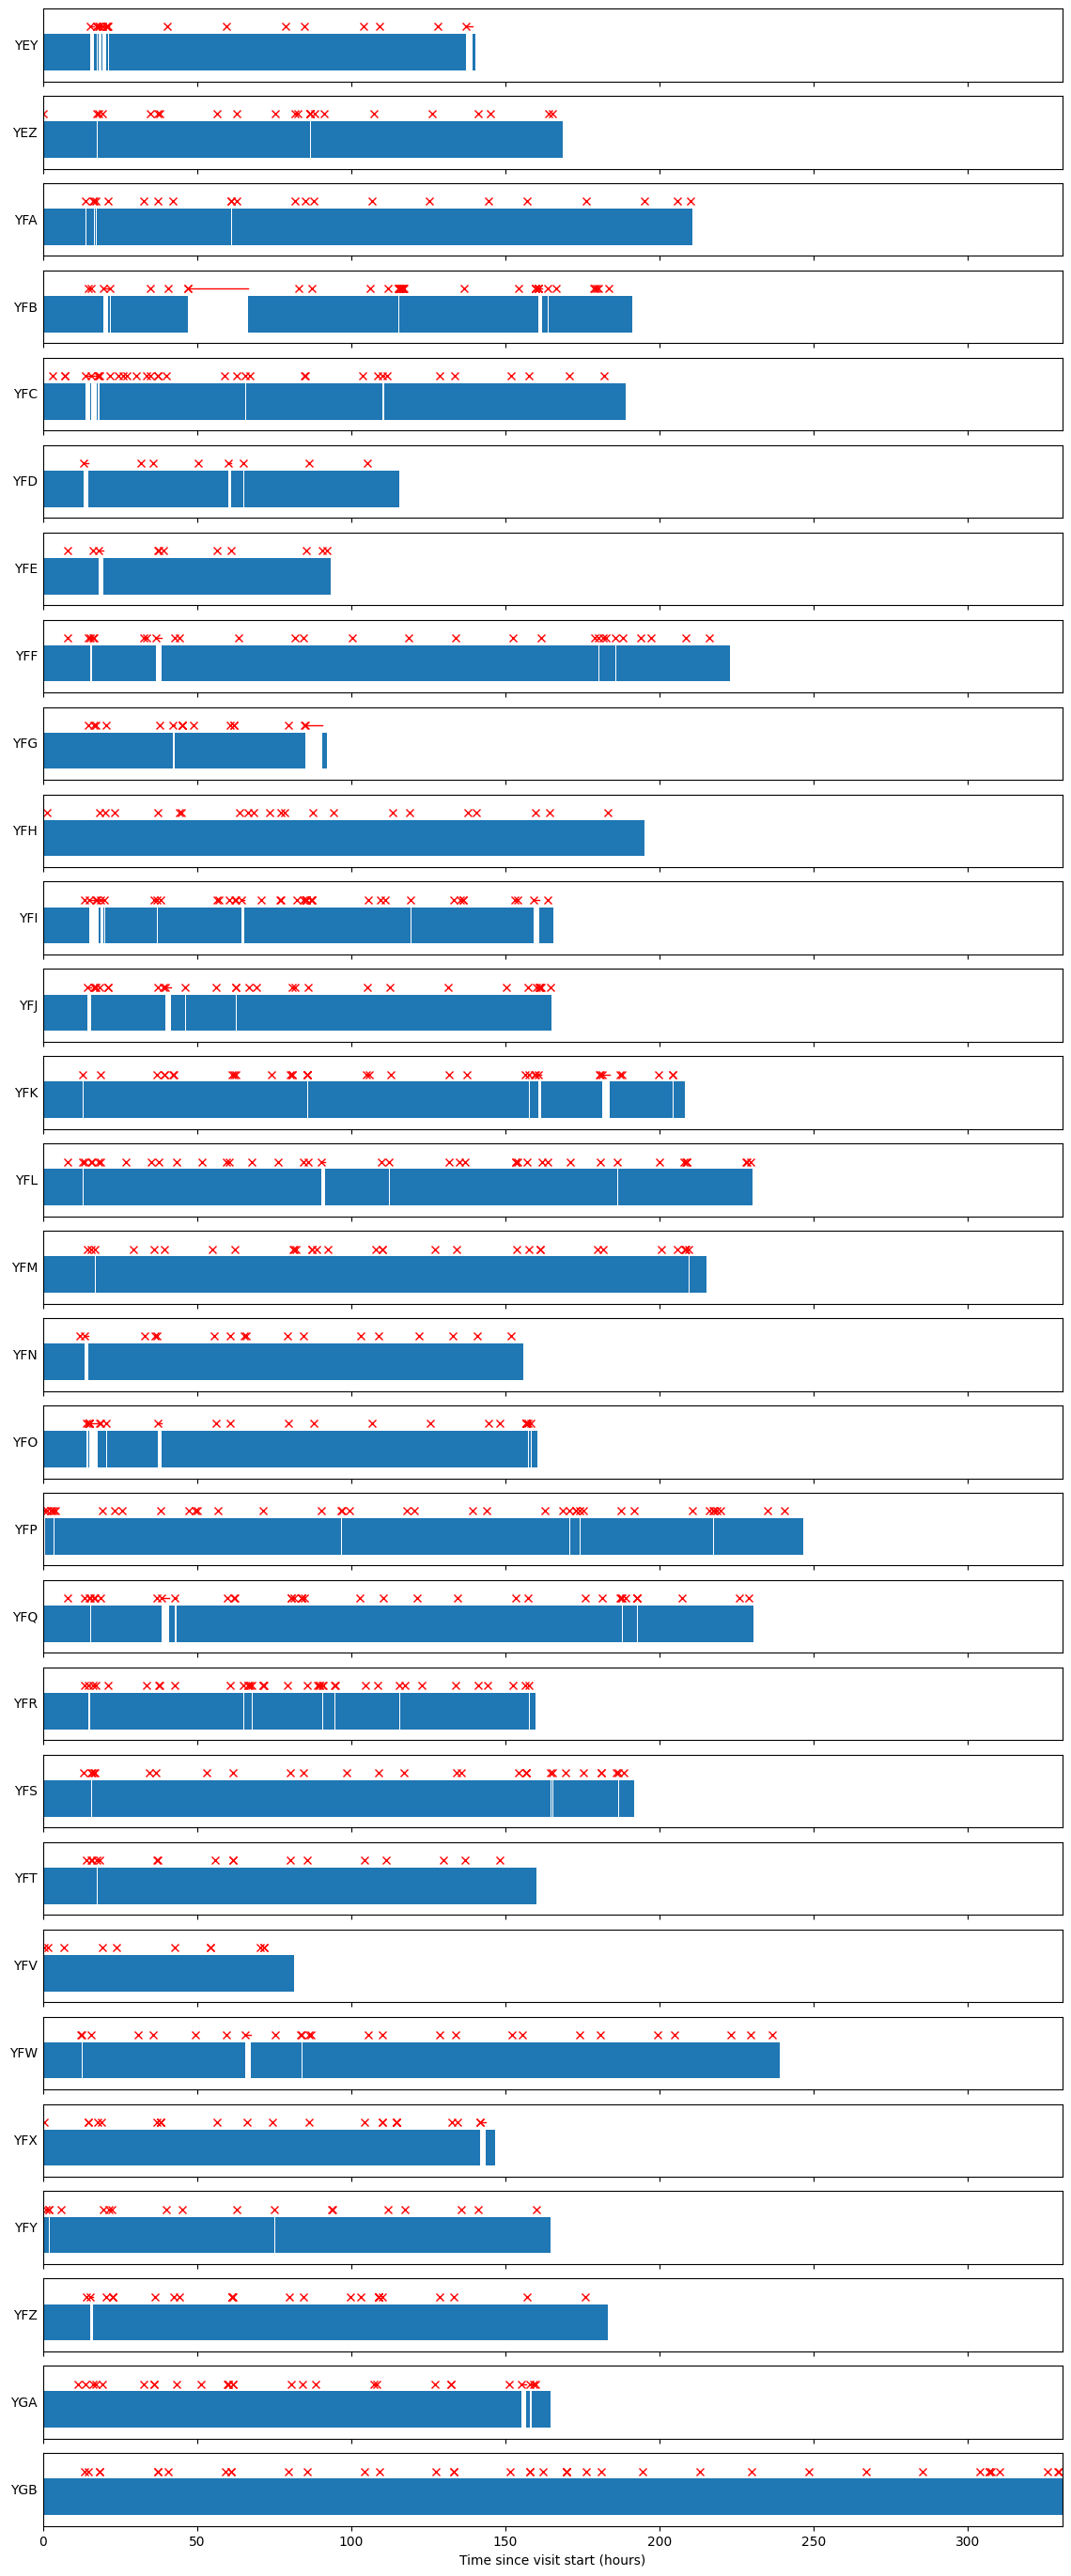

Saved to patient_timelines.png


In [9]:
SHORT_GAP_THRESHOLD_MINUTES = 10  # gaps shorter than this show as a single point only
TIMELINE_PNG_PATH = '../patient_timelines.png'


def plot_patient_timeline(ax, emu_id, good_df, gap_df, visits_df, short_gap_threshold_minutes=SHORT_GAP_THRESHOLD_MINUTES):
    """
    Draw one patient's whole recording time course onto `ax`, x-axis as hours elapsed since
    the start of the visit (visits_df's recording_start_utc), not absolute time. Available
    (good) data is a filled blue band, gaps are red markers above it. A gap shorter than
    short_gap_threshold_minutes is a single point at its midpoint; a longer gap also gets a
    thin line spanning its full duration, so its extent is visible, not just its presence.
    """
    patient_good = good_df[good_df['emu_id'] == emu_id]
    patient_gaps = gap_df[gap_df['emu_id'] == emu_id]
    visit_start = visits_df.loc[visits_df['emu_id'] == emu_id, 'recording_start_utc'].min()

    def elapsed_hours(timestamp):
        return (timestamp - visit_start).total_seconds() / 3600

    bars = [
        (elapsed_hours(row['good_start_utc']), elapsed_hours(row['good_end_utc']) - elapsed_hours(row['good_start_utc']))
        for _, row in patient_good.iterrows()
    ]
    ax.broken_barh(bars, (0, 1), facecolors='tab:blue')

    threshold_hours = short_gap_threshold_minutes / 60
    marker_y = 1.2
    for _, gap in patient_gaps.iterrows():
        start, end = elapsed_hours(gap['gap_start_utc']), elapsed_hours(gap['gap_end_utc'])
        if (end - start) >= threshold_hours:
            ax.plot([start, end], [marker_y, marker_y], color='red', linewidth=1)
        ax.plot(start, marker_y, marker='x', color='red', linestyle='None')

    ax.set_ylim(-0.3, 1.7)
    ax.set_yticks([])
    ax.set_ylabel(str(emu_id), rotation=0, ha='right', va='center')


patients = sorted(set(good_intervals['emu_id']) | set(gaps['emu_id']))
shared_xlim = (0, visits['total_span_hours'].max())

fig, axes = plt.subplots(len(patients), 1, figsize=(14, 1.2 * len(patients)), sharex=True)
for ax, emu_id in zip(axes, patients):
    plot_patient_timeline(ax, emu_id, good_intervals, gaps, visits)

axes[0].set_xlim(shared_xlim)  # shared via sharex=True, so setting it once applies to all
for ax in axes[:-1]:
    ax.tick_params(labelbottom=False)  # sharex links the ticks, not their label visibility
axes[-1].set_xlabel('Time since visit start (hours)')
plt.show()
print(f'Saved to {TIMELINE_PNG_PATH}')

## Patient cohort filter

Splits patients into `older`/`newer` cohorts by their 3-letter `emu_id` (lexicographic comparison against `PATIENT_COHORT_CUTOFF` - **edit this to the actual boundary patient ID**). `COHORT_FILTER` controls which cohort the pooled-distribution cells below use (`'older'`, `'newer'`, or `'all'` for no filtering); change it and re-run this cell and the ones after it to switch cohorts.

In [10]:
PATIENT_COHORT_CUTOFF = 'YFR'  # EDIT ME: patients with emu_id >= this are "newer", else "older"
COHORT_FILTER = 'all'  # 'older', 'newer', or 'all' - which cohort the cells below use

TINY_GAP_THRESHOLD_SECONDS = 0.1  # gaps shorter than this are the "instantaneous" class
BIG_GAP_THRESHOLD_SECONDS = 3*60
TIME_BIN_HOURS = 1  # width of each elapsed-time bin below
WORKING_HOURS = (9, 17)  # 9am-5pm, highlighted on the plots below


def patient_cohort(emu_id):
    """'newer' if emu_id >= PATIENT_COHORT_CUTOFF (lexicographic), else 'older'."""
    return 'newer' if str(emu_id) >= PATIENT_COHORT_CUTOFF else 'older'


def filter_by_cohort(df, cohort_filter=COHORT_FILTER):
    """Restrict df to rows whose emu_id falls in the requested cohort ('older'/'newer'/'all')."""
    if cohort_filter == 'all':
        return df
    return df[df['emu_id'].map(patient_cohort) == cohort_filter]


gaps_filtered = filter_by_cohort(gaps)
good_intervals_filtered = filter_by_cohort(good_intervals)
print(
    f"COHORT_FILTER='{COHORT_FILTER}': {gaps_filtered['emu_id'].nunique()} patient(s), "
    f"{len(gaps_filtered)} gap(s), {len(good_intervals_filtered)} good interval(s)"
)

COHORT_FILTER='all': 29 patient(s), 793 gap(s), 814 good interval(s)


## Shared stacking helpers

`stacked_bars`/`raw_values_by_group` (imported from `plotting_utils.py`, generic across notebooks) plus `per_group_overlap` (below, specific to this notebook's overlap-duration computation) are used by every "colored by patient"/"colored by category" section below, for both the elapsed-time-since-visit-start and time-of-day distributions.

In [11]:
def per_group_overlap(df, start_col, end_col, bin_edges, group_col, groups_in_order, overlap_fn):
    """{group: overlap_duration array} for every group in groups_in_order (zeros if that
    group has no rows in df). overlap_fn is whichever bin-overlap function matches the
    bin semantics - overlap_duration_per_bin for elapsed-time bins, or
    time_of_day_overlap_per_bin for hour-of-day bins (which also wraps at midnight)."""
    return {
        group: overlap_fn(
            df.loc[df[group_col] == group, start_col], df.loc[df[group_col] == group, end_col], bin_edges
        )
        for group in groups_in_order
    }

## Distribution over time since visit start (all patients pooled)

Collapses across patients to show when, relative to the start of a visit, data tends to be available versus when gaps tend to occur. Data availability is the total number of hours of good data falling in each elapsed-time bin, summed across every patient's good intervals (an interval spanning a bin boundary contributes only its overlapping portion to each bin, not its full duration to one). Gaps are split into three duration classes - `< 1s`, `1s-10min`, `> 10min` - and each shown as a count of gaps starting in that bin, so the shape of each class's distribution over the visit timeline can be compared.

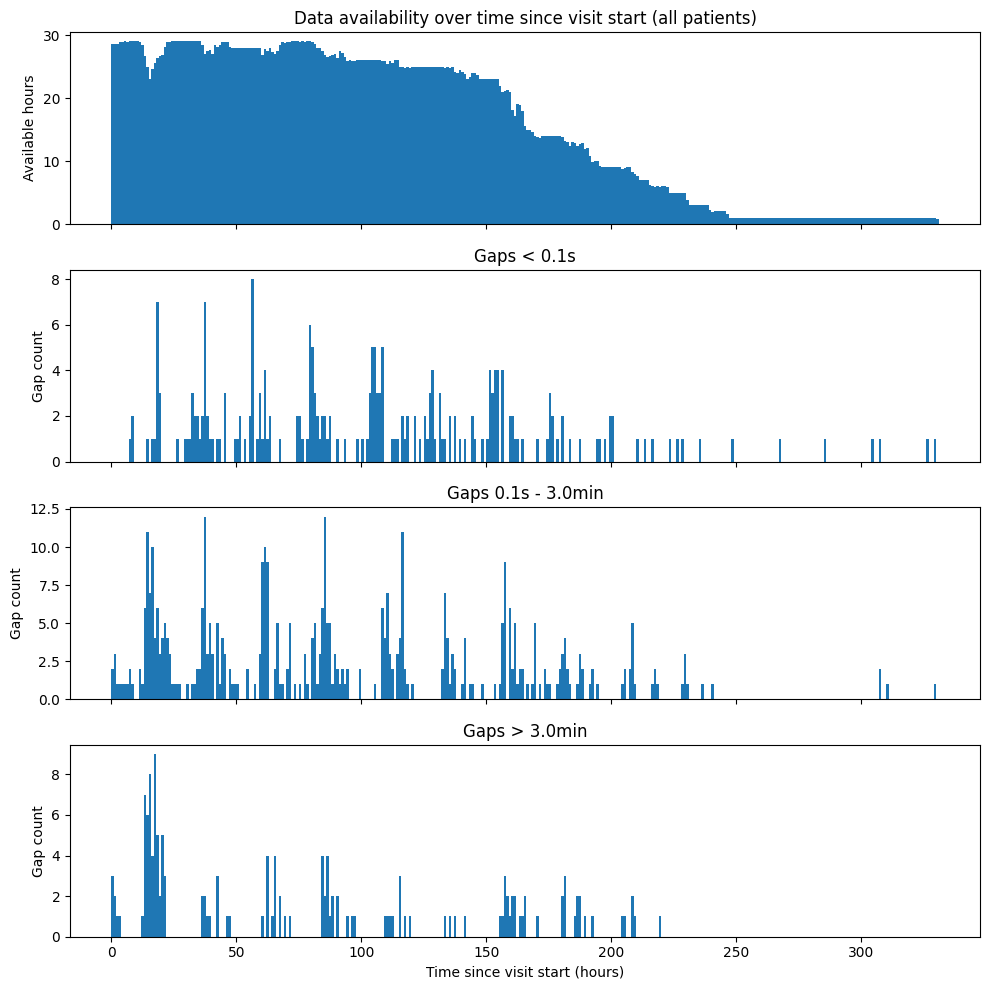

In [12]:


def with_elapsed_hours(df, start_col, end_col, visits_df):
    """
    Add elapsed_start_hours/elapsed_end_hours columns to a copy of df, each row's elapsed
    time measured from ITS OWN patient's visit start (visits_df's recording_start_utc) -
    same convention as plot_patient_timeline above.
    """
    visit_start_by_patient = visits_df.groupby('emu_id')['recording_start_utc'].min()
    visit_start = df['emu_id'].map(visit_start_by_patient)
    out = df.copy()
    out['elapsed_start_hours'] = (df[start_col] - visit_start).dt.total_seconds() / 3600
    out['elapsed_end_hours'] = (df[end_col] - visit_start).dt.total_seconds() / 3600
    return out


def overlap_duration_per_bin(starts, ends, bin_edges):
    """
    For each bin [bin_edges[i], bin_edges[i+1]), sum the overlap duration of every
    (start, end) interval with that bin - i.e. total interval-hours per elapsed-time bin,
    pooled across whatever intervals are passed in (e.g. every patient's good intervals).
    An interval spanning a bin boundary contributes only its overlapping portion to each
    bin, not its full duration to one.
    """
    starts = np.asarray(starts)
    ends = np.asarray(ends)
    totals = np.zeros(len(bin_edges) - 1)
    for i in range(len(bin_edges) - 1):
        b0, b1 = bin_edges[i], bin_edges[i + 1]
        overlap = np.clip(np.minimum(ends, b1) - np.maximum(starts, b0), 0, None)
        totals[i] = overlap.sum()
    return totals


good_elapsed = with_elapsed_hours(good_intervals_filtered, 'good_start_utc', 'good_end_utc', visits)
gaps_elapsed = with_elapsed_hours(gaps_filtered, 'gap_start_utc', 'gap_end_utc', visits)

max_elapsed = visits['total_span_hours'].max()
bin_edges = np.arange(0, max_elapsed + TIME_BIN_HOURS, TIME_BIN_HOURS)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

tiny = gaps_elapsed['duration_hours'] < TINY_GAP_THRESHOLD_SECONDS / 3600
long = gaps_elapsed['duration_hours'] >= BIG_GAP_THRESHOLD_SECONDS / 3600
gap_classes = {
    f'Gaps < {TINY_GAP_THRESHOLD_SECONDS}s': gaps_elapsed[tiny],
    f'Gaps {TINY_GAP_THRESHOLD_SECONDS}s - {BIG_GAP_THRESHOLD_SECONDS/60}min': gaps_elapsed[~tiny & ~long],
    f'Gaps > {BIG_GAP_THRESHOLD_SECONDS/60}min': gaps_elapsed[long],
}

fig, axes = plt.subplots(1 + len(gap_classes), 1, figsize=(10, 2.5 * (1 + len(gap_classes))), sharex=True)

availability_hours = overlap_duration_per_bin(
    good_elapsed['elapsed_start_hours'], good_elapsed['elapsed_end_hours'], bin_edges
)
axes[0].bar(bin_centers, availability_hours, width=TIME_BIN_HOURS)
axes[0].set_ylabel('Available hours')
axes[0].set_title('Data availability over time since visit start (all patients)')

for ax, (label, subset) in zip(axes[1:], gap_classes.items()):
    ax.hist(subset['elapsed_start_hours'], bins=bin_edges)
    ax.set_ylabel('Gap count')
    ax.set_title(label)

for ax in axes[:-1]:
    ax.tick_params(labelbottom=False)
axes[-1].set_xlabel('Time since visit start (hours)')
plt.tight_layout()
plt.show()

## Distribution over time since visit start, colored by patient

Same layout as the previous section, but each panel is stacked by patient (via `stacked_bars`/`raw_values_by_group` above), same approach as the time-of-day-by-patient section further down.

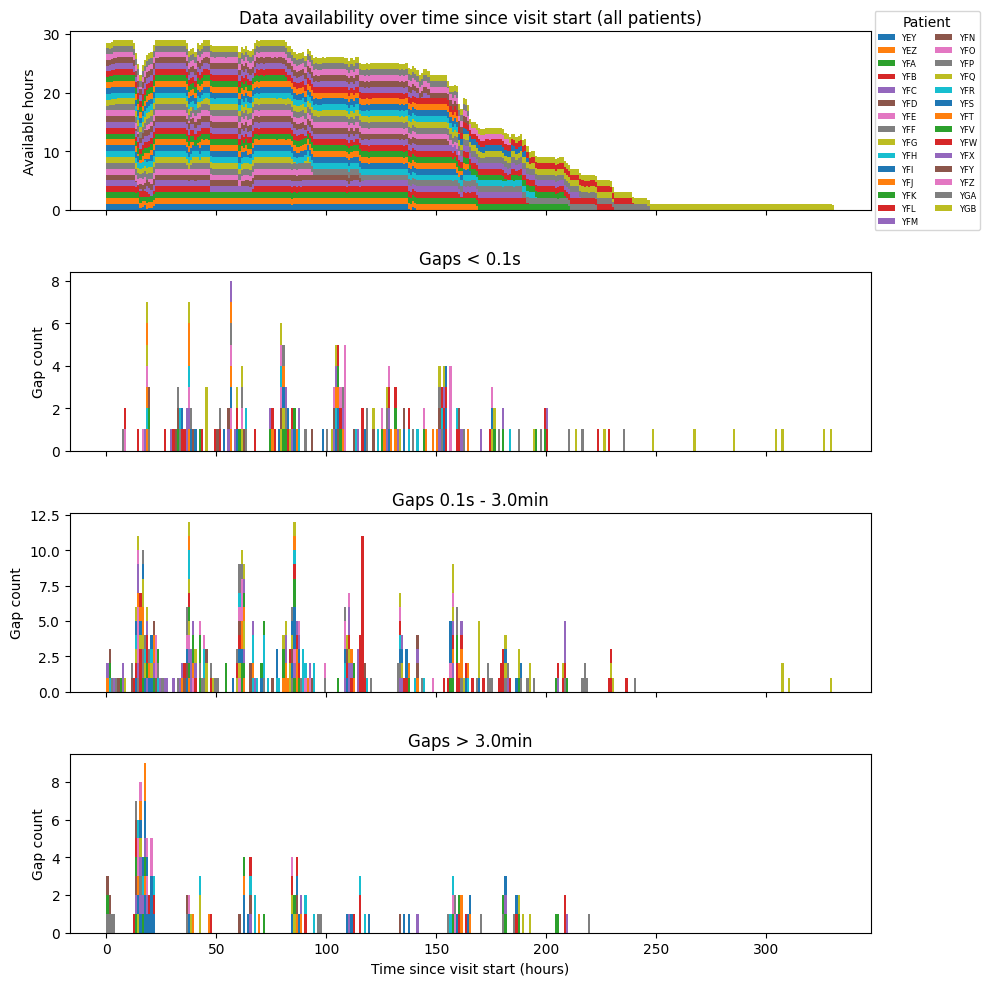

In [13]:
all_patients_elapsed = sorted(set(good_intervals_filtered['emu_id']) | set(gaps_filtered['emu_id']))

fig, axes = plt.subplots(1 + len(gap_classes), 1, figsize=(10, 2.5 * (1 + len(gap_classes))), sharex=True)

availability_by_patient_elapsed = per_group_overlap(
    good_elapsed, 'elapsed_start_hours', 'elapsed_end_hours', bin_edges,
    'emu_id', all_patients_elapsed, overlap_duration_per_bin,
)
stacked_bars(axes[0], bin_centers, TIME_BIN_HOURS, availability_by_patient_elapsed)
axes[0].set_ylabel('Available hours')
axes[0].set_title('Data availability over time since visit start (all patients)')
axes[0].legend(loc='center left', bbox_to_anchor=(1.0, 0.5), fontsize=6, ncol=2, title='Patient')

for ax, (label, subset) in zip(axes[1:], gap_classes.items()):
    values = raw_values_by_group(subset, 'elapsed_start_hours', 'emu_id', all_patients_elapsed)
    ax.hist(values, bins=bin_edges, stacked=True, histtype='bar', label=all_patients_elapsed)
    ax.set_ylabel('Gap count')
    ax.set_title(label)

for ax in axes[:-1]:
    ax.tick_params(labelbottom=False)
axes[-1].set_xlabel('Time since visit start (hours)')
plt.tight_layout()
plt.show()

## Distribution over time since visit start, colored by gap category

Same layout again, gap panels stacked by `category` (from `gaps.csv` - see `scripts/discontinuity_types.md`)
instead of patient. Availability has no `category`, so it reuses `availability_hours` (the plain total
from the first elapsed-time section above) as a single bar, same as the time-of-day-by-category section does
for its own availability panel.

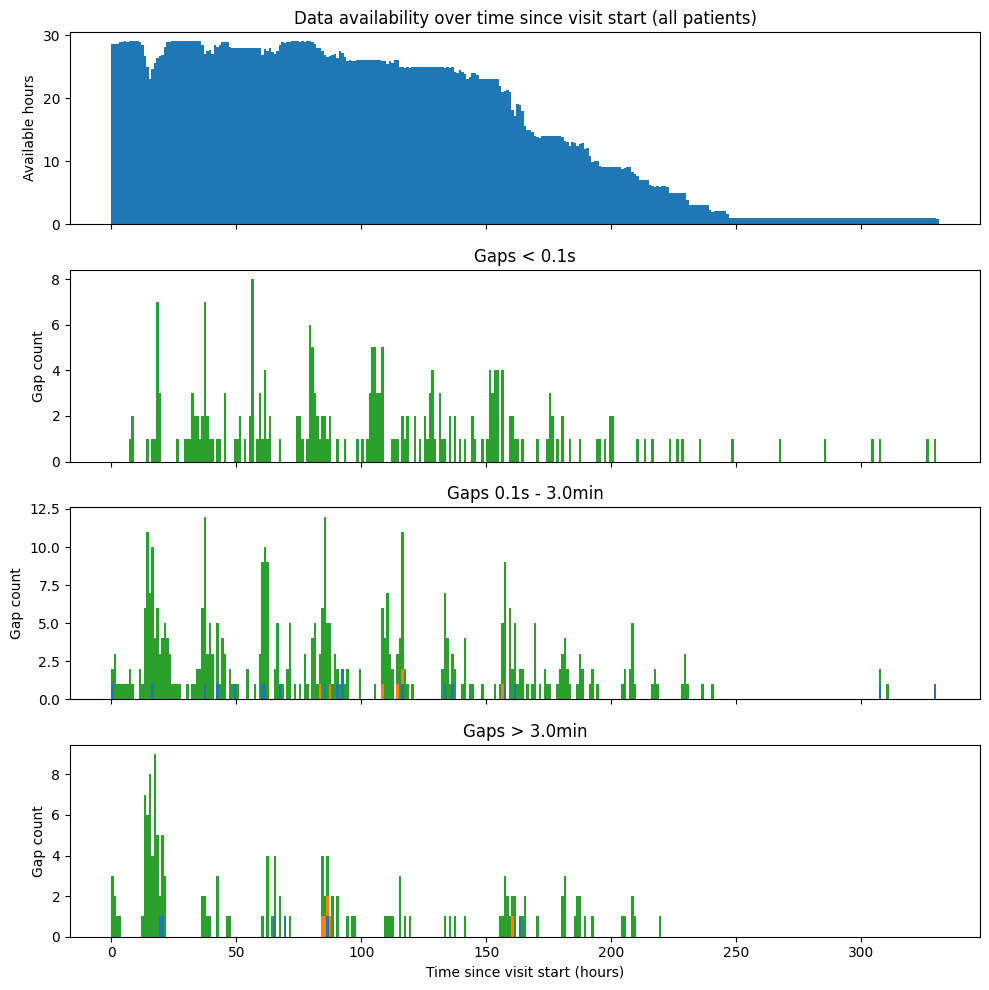

In [14]:
all_categories_elapsed = sorted(gaps_filtered['category'].unique())

fig, axes = plt.subplots(1 + len(gap_classes), 1, figsize=(10, 2.5 * (1 + len(gap_classes))), sharex=True)

axes[0].bar(bin_centers, availability_hours, width=TIME_BIN_HOURS)
axes[0].set_ylabel('Available hours')
axes[0].set_title('Data availability over time since visit start (all patients)')

for ax, (label, subset) in zip(axes[1:], gap_classes.items()):
    values = raw_values_by_group(subset, 'elapsed_start_hours', 'category', all_categories_elapsed)
    ax.hist(values, bins=bin_edges, stacked=True, histtype='bar', label=all_categories_elapsed)
    ax.set_ylabel('Gap count')
    ax.set_title(label)

for ax in axes[:-1]:
    ax.tick_params(labelbottom=False)
axes[-1].set_xlabel('Time since visit start (hours)')
plt.tight_layout()
plt.show()

## Distribution over time of day (all patients pooled)

Same as the previous section, but pooled by hour of day, US/Central time (converted from the UTC timestamps in the CSVs, DST-aware), instead of elapsed time since visit start. A good interval can span midnight (or several days), so its duration is folded onto the 24-hour clock day by day and only the overlapping portion of each day segment is credited to each hour-of-day bin - same overlap principle as before, just wrapped. Gap classes use each gap's own start hour of day, as before.

Each bar is stacked by patient, using matplotlib's own default color cycle (per the [stacked-histogram example](https://matplotlib.org/stable/gallery/statistics/histogram_multihist.html)) rather than a manually assigned colormap. The default cycle has 10 colors, so with more than 10 patients some will repeat.

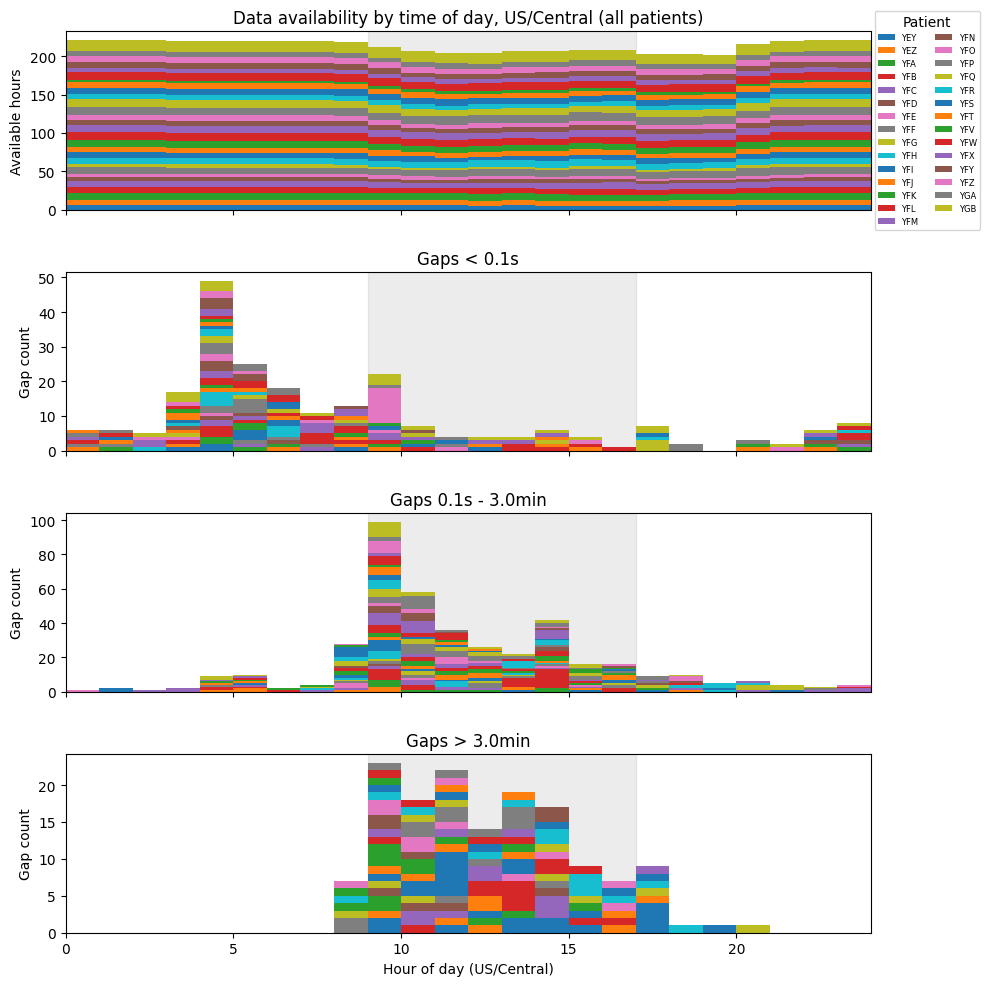

In [15]:
CENTRAL_TZ = 'US/Central'


def to_central(timestamps):
    """Convert naive UTC timestamps (as read from the CSVs) to US/Central, DST-aware."""
    return timestamps.dt.tz_localize('UTC').dt.tz_convert(CENTRAL_TZ)


def hour_of_day(timestamps):
    """Fractional hour of day, in [0, 24), for a tz-aware datetime Series."""
    return (timestamps - timestamps.dt.normalize()).dt.total_seconds() / 3600


def split_into_day_segments(start, end):
    """
    Split [start, end) into segments that each lie within a single calendar day (in
    whatever timezone start/end are already in). Uses DateOffset, not Timedelta, for the
    day step, so a segment boundary lands on local midnight even across a DST transition.
    """
    segments = []
    cursor = start
    while cursor < end:
        next_midnight = cursor.normalize() + pd.DateOffset(days=1)
        segment_end = min(end, next_midnight)
        segments.append((cursor, segment_end))
        cursor = segment_end
    return segments


def time_of_day_overlap_per_bin(starts, ends, bin_edges):
    """
    Like overlap_duration_per_bin, but folds each (start, end) interval onto a 24-hour
    clock first (splitting at day boundaries via split_into_day_segments), so an interval
    spanning midnight or multiple days is credited to the hours of day it actually
    covers, each time it covers them.
    """
    totals = np.zeros(len(bin_edges) - 1)
    for start, end in zip(starts, ends):
        for seg_start, seg_end in split_into_day_segments(start, end):
            day_midnight = seg_start.normalize()
            hod_start = (seg_start - day_midnight).total_seconds() / 3600
            hod_end = (seg_end - day_midnight).total_seconds() / 3600
            for i in range(len(bin_edges) - 1):
                b0, b1 = bin_edges[i], bin_edges[i + 1]
                totals[i] += max(0, min(hod_end, b1) - max(hod_start, b0))
    return totals


hod_bin_edges = np.arange(0, 24 + TIME_BIN_HOURS, TIME_BIN_HOURS)
hod_bin_centers = (hod_bin_edges[:-1] + hod_bin_edges[1:]) / 2

gaps_hod = gaps_filtered.assign(hour_of_day=hour_of_day(to_central(gaps_filtered['gap_start_utc'])))
tiny_hod = gaps_hod['duration_hours'] < TINY_GAP_THRESHOLD_SECONDS / 3600
long_hod = gaps_hod['duration_hours'] >= BIG_GAP_THRESHOLD_SECONDS / 3600
gap_classes_hod = {
    f'Gaps < {TINY_GAP_THRESHOLD_SECONDS}s': gaps_hod[tiny_hod],
    f'Gaps {TINY_GAP_THRESHOLD_SECONDS}s - {BIG_GAP_THRESHOLD_SECONDS / 60}min': gaps_hod[~tiny_hod & ~long_hod],
    f'Gaps > {BIG_GAP_THRESHOLD_SECONDS / 60}min': gaps_hod[long_hod],
}

all_patients = sorted(set(good_intervals_filtered['emu_id']) | set(gaps_filtered['emu_id']))

fig, axes = plt.subplots(1 + len(gap_classes_hod), 1, figsize=(10, 2.5 * (1 + len(gap_classes_hod))), sharex=True)
for ax in axes:
    ax.axvspan(*WORKING_HOURS, color='gray', alpha=0.15, zorder=0)

good_intervals_central = good_intervals_filtered.assign(
    good_start_central=to_central(good_intervals_filtered['good_start_utc']),
    good_end_central=to_central(good_intervals_filtered['good_end_utc']),
)
availability_by_patient = per_group_overlap(
    good_intervals_central, 'good_start_central', 'good_end_central', hod_bin_edges,
    'emu_id', all_patients, time_of_day_overlap_per_bin,
)
stacked_bars(axes[0], hod_bin_centers, TIME_BIN_HOURS, availability_by_patient)
axes[0].set_ylabel('Available hours')
axes[0].set_title('Data availability by time of day, US/Central (all patients)')
axes[0].legend(loc='center left', bbox_to_anchor=(1.0, 0.5), fontsize=6, ncol=2, title='Patient')

for ax, (label, subset) in zip(axes[1:], gap_classes_hod.items()):
    values = raw_values_by_group(subset, 'hour_of_day', 'emu_id', all_patients)
    ax.hist(values, bins=hod_bin_edges, stacked=True, histtype='bar', label=all_patients)
    ax.set_ylabel('Gap count')
    ax.set_title(label)

for ax in axes[:-1]:
    ax.tick_params(labelbottom=False)
axes[-1].set_xlabel('Hour of day (US/Central)')
axes[-1].set_xlim(0, 24)
plt.tight_layout()
plt.show()

## Distribution over time of day, colored by gap category (all patients pooled)

Same layout as the previous section, but each gap panel is stacked by `category` (from `gaps.csv` -
see `scripts/discontinuity_types.md`) instead of by patient - again via `ax.hist(..., stacked=True)`
so matplotlib handles the stacking and coloring. Availability has no `category` (it isn't a property
of a good interval), so it stays a single plain bar, as in the very first version of this figure.

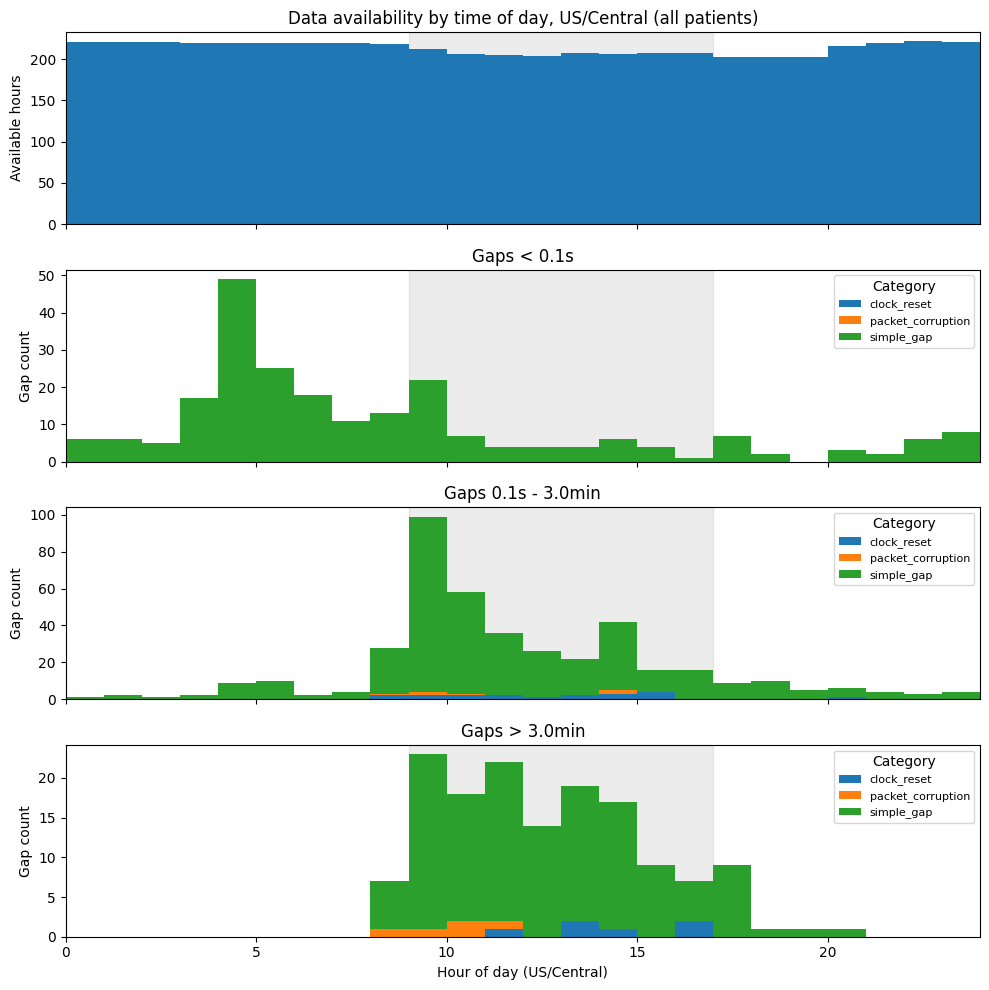

In [16]:
all_categories = sorted(gaps_filtered['category'].unique())


availability_hours_hod_total = time_of_day_overlap_per_bin(
    good_intervals_central['good_start_central'], good_intervals_central['good_end_central'], hod_bin_edges
)

fig, axes = plt.subplots(1 + len(gap_classes_hod), 1, figsize=(10, 2.5 * (1 + len(gap_classes_hod))), sharex=True)
for ax in axes:
    ax.axvspan(*WORKING_HOURS, color='gray', alpha=0.15, zorder=0)

axes[0].bar(hod_bin_centers, availability_hours_hod_total, width=TIME_BIN_HOURS)
axes[0].set_ylabel('Available hours')
axes[0].set_title('Data availability by time of day, US/Central (all patients)')

for ax, (label, subset) in zip(axes[1:], gap_classes_hod.items()):
    values = raw_values_by_group(subset, 'hour_of_day', 'category', all_categories)
    ax.hist(values, bins=hod_bin_edges, stacked=True, histtype='bar', label=all_categories)
    ax.set_ylabel('Gap count')
    ax.set_title(label)
    ax.legend(fontsize=8, title='Category')

for ax in axes[:-1]:
    ax.tick_params(labelbottom=False)
axes[-1].set_xlabel('Hour of day (US/Central)')
axes[-1].set_xlim(0, 24)
plt.tight_layout()
plt.show()

## Tiny 'other'-cause gaps: BRK timestamp before the glitch, and time since the last TOC reset

Looks specifically at gaps in the shortest duration class (`< TINY_GAP_THRESHOLD_SECONDS`, the same threshold used above) with `cause == 'other'` - i.e. the clock-glitch-sized anomalies, not TOC resets or file edges. For each one: `brk_ts_before` is already a column in `discontinuity_labeled.csv` (the raw tick immediately before the glitch); `hours_since_last_toc_reset` is computed here via an as-of join against every `TOC reset`-cause row in the same admission, taking the most recent one whose `gap_end_utc` (when the new TOC actually started) is at or before this glitch's `gap_start_utc`. Comparison is in UTC, not raw ticks, since ticks aren't comparable across a TOC boundary (established earlier in this project). A glitch with no prior TOC reset in its admission (e.g. one inside the very first TOC) gets `NaT`/`NaN` for those columns.

Uses `disc_labeled` (the full raw discontinuity log, `cause`/`insane`/`brk_ts_before` intact), not `gaps` - this is a diagnostic look at the raw data, not the reduced/corrected gap list, and not part of the cohort comparison above.

In [17]:
toc_resets = (
    disc_labeled.loc[disc_labeled['cause'] == 'TOC reset', ['patient_id', 'admission_id', 'gap_end_utc']]
    .rename(columns={'gap_end_utc': 'last_toc_reset_utc'})
    .sort_values('last_toc_reset_utc')
)

tiny_other = disc_labeled[
    (disc_labeled['duration_hours'] < TINY_GAP_THRESHOLD_SECONDS / 3600) & (disc_labeled['cause'] == 'other')
].sort_values('gap_start_utc')

tiny_other_annotated = pd.merge_asof(
    tiny_other,
    toc_resets,
    left_on='gap_start_utc',
    right_on='last_toc_reset_utc',
    by=['patient_id', 'admission_id'],
    direction='backward',
)
tiny_other_annotated['hours_since_last_toc_reset'] = (
    tiny_other_annotated['gap_start_utc'] - tiny_other_annotated['last_toc_reset_utc']
).dt.total_seconds() / 3600

tiny_other_annotated['dist_to_32bit_rollover'] = tiny_other_annotated['brk_ts_before'] - (2**32 * (np.round(tiny_other_annotated['brk_ts_before'] / 2**32)))
tiny_other_annotated['time_to_32bit_rollover'] = tiny_other_annotated['hours_since_last_toc_reset'] - (19.88 * (np.round(tiny_other_annotated['hours_since_last_toc_reset'] / 19.88)))


print(f'{len(tiny_other_annotated)} tiny "other"-cause gap(s)')

plt.figure()
plt.subplot(2, 2, 1)
plt.hist(tiny_other_annotated['hours_since_last_toc_reset'])
ylim = plt.gca().get_ylim()
plt.plot([19.88, 19.88], [ylim, ylim], linestyle='--')
plt.ylim(ylim)
plt.xlabel('Time since last TOC reset')
plt.subplot(2, 2, 2)
plt.hist(tiny_other_annotated['time_to_32bit_rollover'])
plt.xlabel('Time to nearest expected 32 bit rollover')
plt.subplot(2, 2, 3)
plt.hist(tiny_other_annotated['brk_ts_before'])
ylim = plt.gca().get_ylim()
plt.plot([2**32, 2**32], [ylim, ylim], linestyle='--')
plt.ylim(ylim)
plt.xlabel('BRK ticks before stutter')
plt.subplot(2, 2, 4)
plt.hist(tiny_other_annotated['dist_to_32bit_rollover'])
plt.xlabel('BRK ticks to 32 bit rollover')
plt.tight_layout()

tiny_other_annotated[[
    'emu_id', 'gap_start_utc',
    'brk_ts_before', 'dist_to_32bit_rollover',
    'last_toc_reset_utc', 'hours_since_last_toc_reset', 'time_to_32bit_rollover'
]]

MergeError: Incompatible merge dtype, dtype('O') and dtype('O'), both sides must have numeric dtype

## TOC-reset gaps between 3 and 15 minutes: total duration per patient

Filters `disc_labeled` to `cause == 'TOC reset'` with `duration_hours` between `TOC_RESET_MIN_MINUTES` and `TOC_RESET_MAX_MINUTES` (inclusive), then sums duration per patient. Uses `disc_labeled` (the full raw discontinuity log), not `gaps` - same as the tiny-gap section above, this is a diagnostic look at the raw data, not the reduced/corrected gap list.

In [ ]:
TOC_RESET_MIN_MINUTES = 3
TOC_RESET_MAX_MINUTES = 15

toc_reset_midlength = disc_labeled[
    (disc_labeled['cause'] == 'TOC reset')
    & (disc_labeled['duration_hours'] >= TOC_RESET_MIN_MINUTES / 60)
    & (disc_labeled['duration_hours'] <= TOC_RESET_MAX_MINUTES / 60)
]

toc_reset_midlength_summary = (
    toc_reset_midlength
    .groupby('emu_id')
    .agg(n_gaps=('duration_hours', 'size'), total_duration_hours=('duration_hours', 'sum'))
    .assign(total_duration_minutes=lambda d: d['total_duration_hours'] * 60)
    .sort_values('total_duration_hours', ascending=False)
)

print(
    f'{len(toc_reset_midlength)} TOC-reset gap(s) between {TOC_RESET_MIN_MINUTES} and '
    f'{TOC_RESET_MAX_MINUTES} minutes, across {toc_reset_midlength_summary.shape[0]} patient(s)'
)
print(f'Total duration: {sum(toc_reset_midlength_summary["total_duration_hours"])}')
toc_reset_midlength_summary